# Review Decoder - исследовательский анализ данных

In [1]:
import kagglehub
from pathlib import Path
import re
import hashlib
import importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import html
from matplotlib.ticker import PercentFormatter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 120,
                     'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
LABELS = {0: 'Не рекомендует', 1: 'Рекомендует'}
COLORS = {0: '#D8794D', 1: '#397DA8'}

## 1. Загрузка и проверка данных


In [2]:
filename = 'Womens Clothing E-Commerce Reviews.csv'
path = kagglehub.dataset_download("nicapotato/womens-ecommerce-clothing-reviews")
csv_path = Path(path) / filename
raw = pd.read_csv(csv_path)

df = raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed:')]).copy()
required = {'Review Text', 'Recommended IND', 'Rating', 'Class Name', 'Clothing ID'}

print(f'Размер: {len(df):,} строк × {df.shape[1]} содержательных столбцов')
display(df.head(3))

100%|██████████| 2.79M/2.79M [00:00<00:00, 45.1MB/s]

Extracting files...


Размер: 23,486 строк × 10 содержательных столбцов


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3,0,0,General,Dresses,Dresses


In [3]:
pd.DataFrame({'Тип': df.dtypes.astype(str), 'Уникальных': df.nunique()})

,Тип,Уникальных
Clothing ID,int64,1206
Age,int64,77
Title,object,13993
Review Text,object,22634
Rating,int64,5
Recommended IND,int64,2
Positive Feedback Count,int64,82
Division Name,object,3
Department Name,object,6
Class Name,object,20


,Пропуски,"Доля, %"
Clothing ID,0,0.00
Age,0,0.00
Title,3810,16.22
Review Text,845,3.60
Rating,0,0.00
Recommended IND,0,0.00
Positive Feedback Count,0,0.00
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06


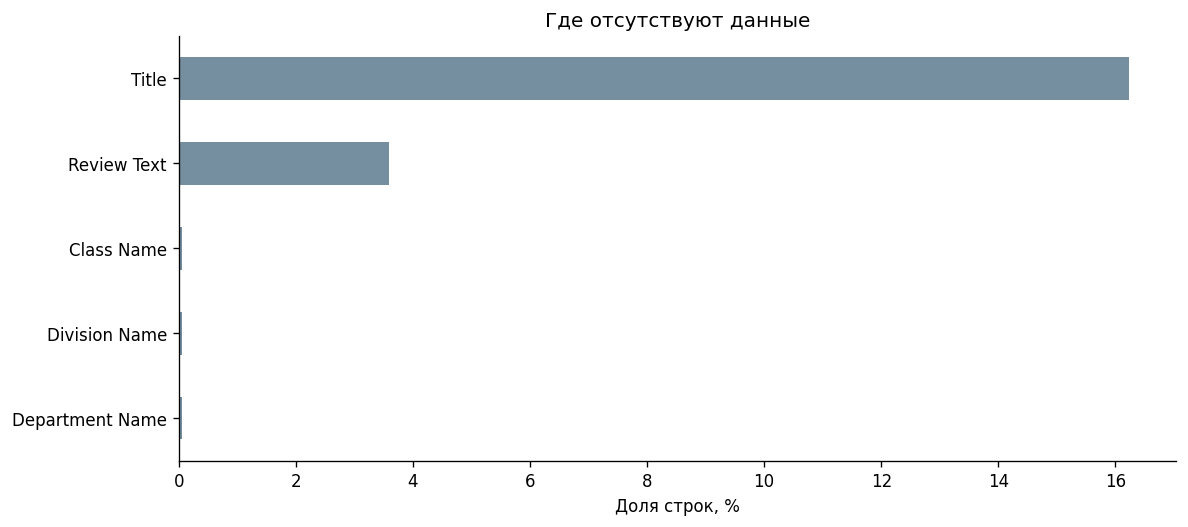

,rows,text_missing_pct,title_missing_pct
class_label,,,
Не рекомендует,4172,1.70,14.31
Рекомендует,19314,4.01,16.64


In [4]:
for col in ['Review Text', 'Title']:
    df[col] = df[col].fillna('').str.strip()
df['has_text'] = df['Review Text'].ne('')
df['has_title'] = df['Title'].ne('')
df['class_label'] = df['Recommended IND'].replace(LABELS)

# Единое определение слова: последовательность латинских букв с возможным апострофом.
def tokens(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower().replace('’', "'"))
df['tokens'] = df['Review Text'].apply(tokens)
df['n_words'] = df['tokens'].apply(len)
df['n_chars'] = df['Review Text'].str.len()
text_df = df.loc[df['has_text']].copy()
missing = raw.isna().sum().drop(labels=[c for c in raw if c.startswith('Unnamed:')])
missing['Review Text'] = (~df['has_text']).sum()
missing['Title'] = (~df['has_title']).sum()
missing_table = pd.DataFrame({'Пропуски': missing, 'Доля, %': missing / len(df) * 100})
display(missing_table.round(2))
missing_table.query('Пропуски > 0')['Доля, %'].sort_values().plot.barh(color='#758FA1')
plt.xlabel('Доля строк, %'); plt.title('Где отсутствуют данные'); plt.tight_layout(); plt.show()

missing_by_target = df.groupby('class_label').agg(
    rows=('has_text', 'size'), text_missing_pct=('has_text', lambda x: 100 * (1-x.mean())),
    title_missing_pct=('has_title', lambda x: 100 * (1-x.mean())))
display(missing_by_target.round(2))
recoverable = ((~df['has_text']) & df['has_title']).sum()

**Вывод.** Без основного текста 845 строк (3.6%). Из них у 1 есть заголовок. Для прогноза только по тексту отзыва такие строки нужно исключить

## 2. Баланс классов
Сравниваем весь датасет и подвыборку с текстом. Это позволяет увидеть, меняется ли баланс после исключения пустых отзывов.

,Все строки,С текстом,"Все строки, %","С текстом, %"
Не рекомендует,4172,4101,17.76,18.11
Рекомендует,19314,18540,82.24,81.89


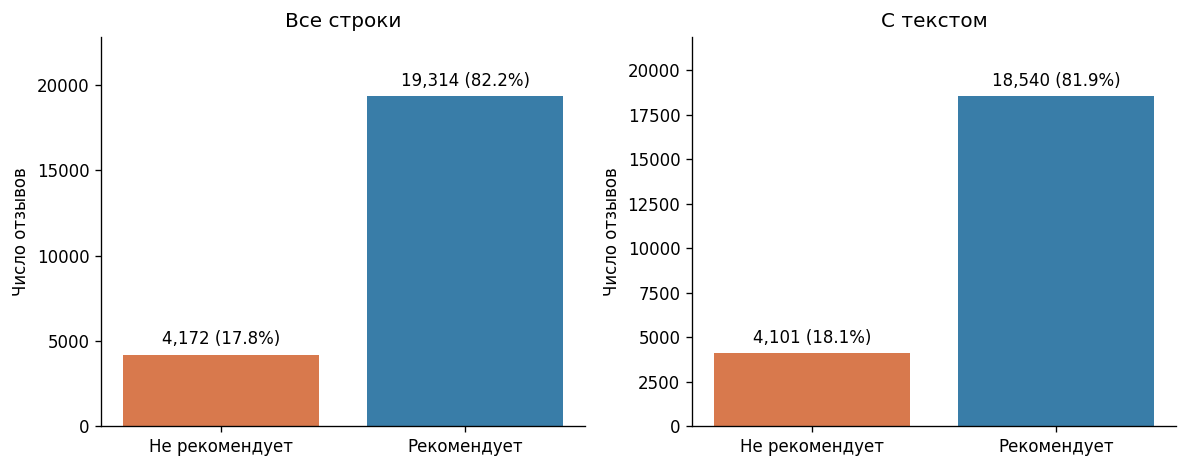

In [5]:
balance = pd.DataFrame({
    'Все строки': df['Recommended IND'].value_counts().reindex([0, 1]),
    'С текстом': text_df['Recommended IND'].value_counts().reindex([0, 1])})
balance.index = [LABELS[i] for i in balance.index]
shares = balance.div(balance.sum(), axis=1) * 100
display(balance.join(shares.add_suffix(', %')).round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, balance.columns):
    bars = ax.bar(balance.index, balance[col], color=[COLORS[0], COLORS[1]])
    ax.bar_label(bars, labels=[f'{v:,} ({p:.1f}%)' for v,p in zip(balance[col], shares[col])], padding=4)
    ax.set_ylim(0, balance[col].max()*1.18); ax.set_title(col); ax.set_ylabel('Число отзывов')
plt.tight_layout(); plt.show()

**Вывод.** Классы не сбалансированы, рекомендаций заметно больше: 82% строк. Аccuracy не стоит использовать в качестве метрки.

## 3. Длина отзывов
Пустые тексты исключены. Считаем слова и символы; показываем медиану, квартильный диапазон и хвост распределения. На гистограмме каждый класс нормирован отдельно

,n,mean_words,median_words,q25_words,q75_words,p95_words,max_words,median_chars
class_label,,,,,,,,
Не рекомендует,4101,61.6,61.0,39.0,88.0,100.0,114,316.0
Рекомендует,18540,59.2,58.0,35.0,88.0,100.0,113,298.0


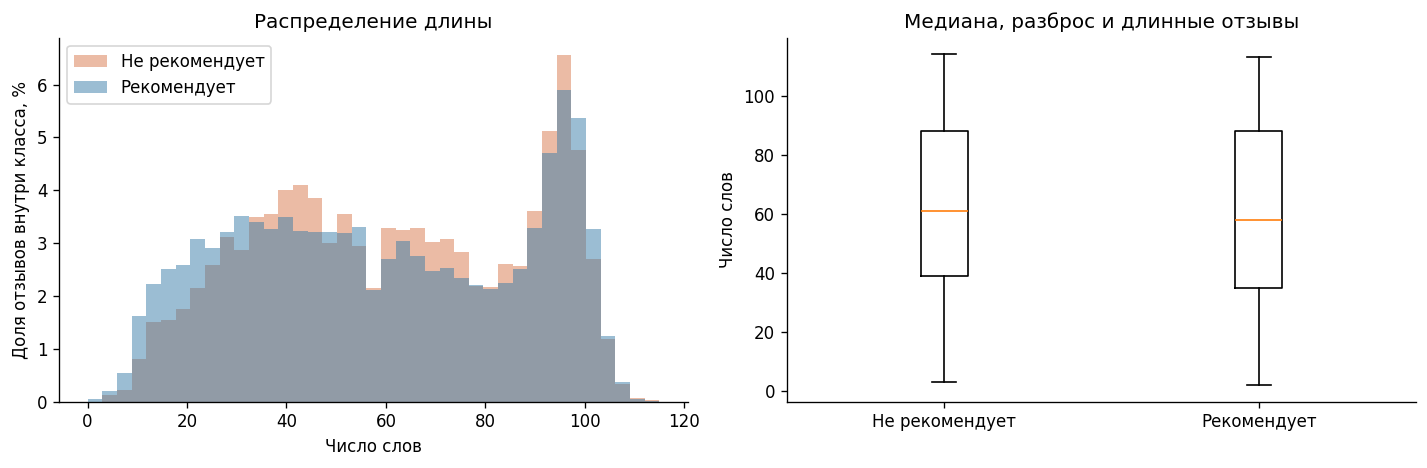

In [6]:
length_stats = text_df.groupby('class_label').agg(
    n=('n_words','size'), mean_words=('n_words','mean'), median_words=('n_words','median'),
    q25_words=('n_words',lambda x:x.quantile(.25)), q75_words=('n_words',lambda x:x.quantile(.75)),
    p95_words=('n_words',lambda x:x.quantile(.95)), max_words=('n_words','max'),
    median_chars=('n_chars','median'))
display(length_stats.round(1))
fig, axes = plt.subplots(1,2,figsize=(12,4))
upper = max(10, int(text_df.n_words.max()))
bins = np.linspace(0, upper+1, 40)
for target in [0,1]:
    x = text_df.loc[text_df['Recommended IND'].eq(target),'n_words']
    axes[0].hist(x, bins=bins, weights=np.ones(len(x))*100/len(x), alpha=.5,
                 color=COLORS[target],label=LABELS[target])
axes[0].set(xlabel='Число слов', ylabel='Доля отзывов внутри класса, %', title='Распределение длины'); axes[0].legend()
axes[1].boxplot([text_df.loc[text_df['Recommended IND'].eq(t),'n_words'] for t in [0,1]],
                tick_labels=[LABELS[t] for t in [0,1]], showfliers=True,
                flierprops={'markersize':2,'alpha':.2})
axes[1].set(ylabel='Число слов',title='Медиана, разброс и длинные отзывы')
plt.tight_layout(); plt.show()
m = text_df.groupby('Recommended IND').n_words.median()

**Вывод.** Медиана длины: 61 слов у нерекомендующих и 58 у рекомендующих. Распределения сильно пересекаются. Длина не дает вывод для определения таргета

## 4. Частотные слова и биграммы
Для Recommended и Not recommended смотрими доли отзывов, содержащих слово или словосочетание хотя бы один раз. В таблицах дополнительно показано общее число вхождений.

Приводим текст к нижнему регистру, раскрываем отрицания: don't → do not, can't → can not, won't → will not.

Для отдельных слов удаляем английские стоп-слова, сохраняя отрицания. Биграммы строим из соседних слов после раскрытия сокращений, не переходя через пунктуацию. Оставляем пары из двух содержательных слов, а также отрицание или усилитель перед содержательным словом: not flattering, too small, very comfortable. Стоп-слова не удаляем до построения пар, чтобы не соединять слова, которые не стояли рядом.

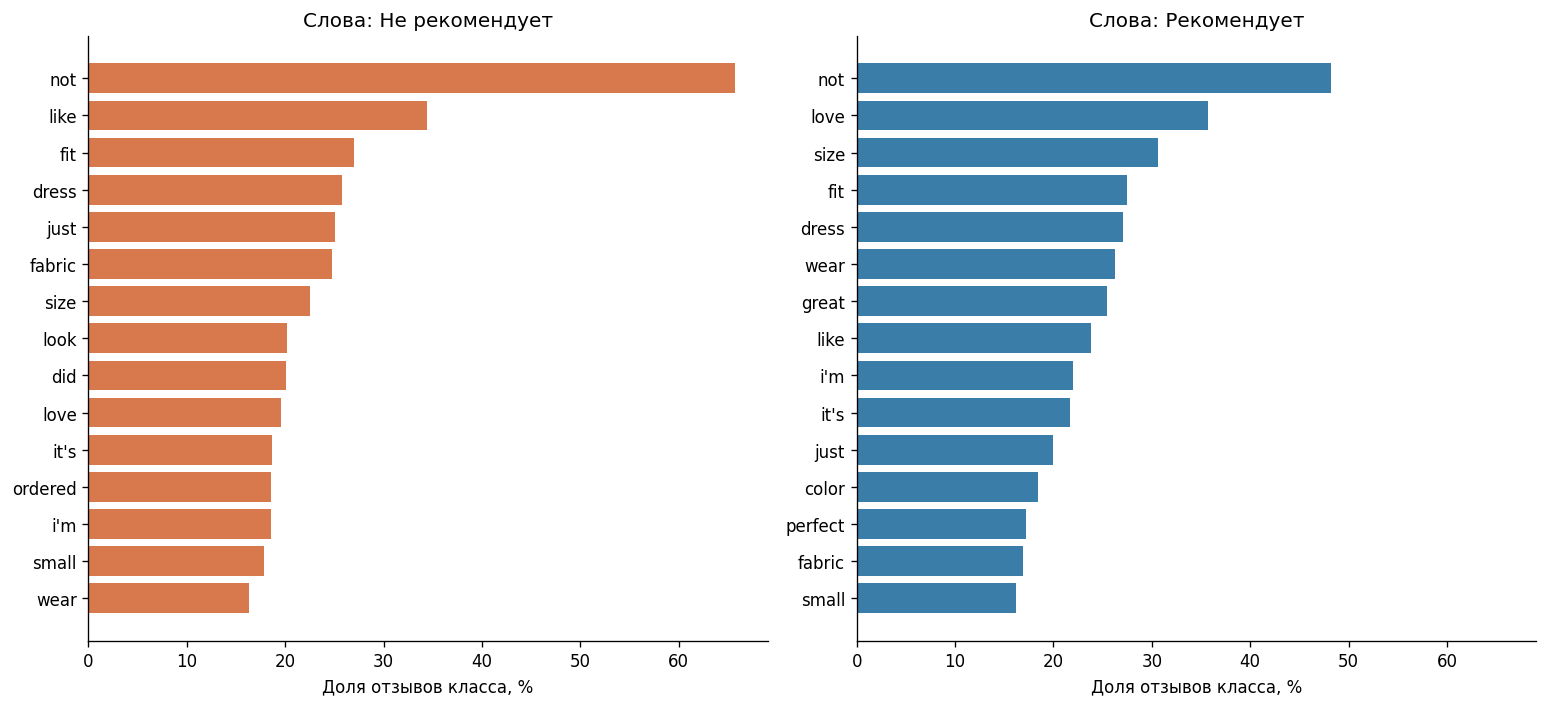

term  occurrences  reviews  reviews_pct
Класс                                                      
Не рекомендует 0     not         4486     2697        65.76
               1    like         1780     1412        34.43
               2     fit         1327     1108        27.02
               3   dress         1974     1058        25.80
               4    just         1252     1028        25.07
               5  fabric         1244     1017        24.80
               6    size         1210      923        22.51
               7    look          965      826        20.14
               8     did         1002      825        20.12
               9    love          928      803        19.58
Рекомендует    0     not        13705     8935        48.19
               1    love         8023     6619        35.70
               2    size         7564     5673        30.60
               3     fit         5994     5090        27.45
               4   dress         8587     5022        27.09
               5    wear         5683     4862        26.22
               6   great         5587     4720        25.46
               7    like         5370     4411        23.79
               8     i'm         4984     4073        21.97
               9    it's         5422     4028        21.73

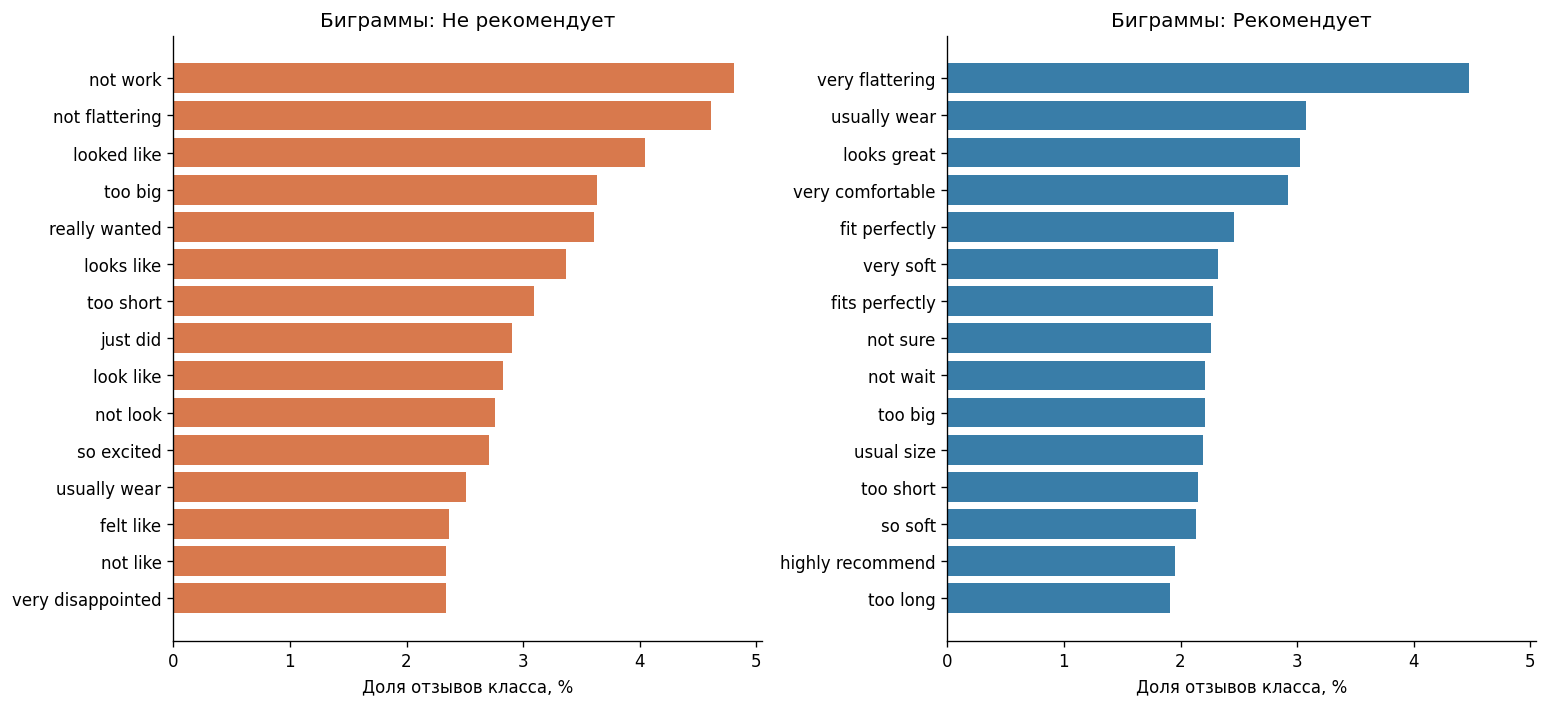

term  occurrences  reviews  reviews_pct
Класс                                                                
Не рекомендует 0          not work          205      197         4.80
               1    not flattering          191      189         4.61
               2       looked like          172      166         4.05
               3           too big          155      149         3.63
               4     really wanted          151      148         3.61
               5        looks like          141      138         3.37
               6         too short          130      127         3.10
               7          just did          126      119         2.90
               8         look like          119      116         2.83
               9          not look          119      113         2.76
Рекомендует    0   very flattering          837      829         4.47
               1      usually wear          571      570         3.07
               2       looks great          567      560         3.02
               3  very comfortable          547      542         2.92
               4     fit perfectly          464      456         2.46
               5         very soft          434      431         2.32
               6    fits perfectly          423      422         2.28
               7          not sure          429      420         2.27
               8          not wait          415      410         2.21
               9           too big          425      409         2.21

In [7]:
negations = {'no', 'not', 'never', 'nor', 'neither'}
modifiers = {'too', 'very', 'really', 'quite', 'extremely', 'so', 'super'}
stop_words = set(ENGLISH_STOP_WORDS) | modifiers

def normalized_segments(text):
    text = html.unescape(text).lower().replace('’', "'")
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bcannot\b", 'can not', text)
    text = re.sub(r"n't\b", ' not', text)
    return [tokens(part) for part in re.split(r"[^a-z'\s]+|[\r\n]+", text)]

def content_word(t):
    return len(t) > 1 and t not in stop_words and t not in negations

def unigrams(text):
    return [t for segment in normalized_segments(text) for t in segment
            if content_word(t) or t in negations]

def bigrams(text):
    result = []
    for segment in normalized_segments(text):
        for a, b in zip(segment, segment[1:]):
            if content_word(b) and (content_word(a) or a in negations or a in modifiers):
                result.append(a + ' ' + b)
    return result

def frequency_table(texts, extractor):
    occurrences, documents = Counter(), Counter()
    for text in texts:
        terms = extractor(text)
        occurrences.update(terms); documents.update(set(terms))
    return pd.DataFrame([{'term':term, 'occurrences':occurrences[term], 'reviews':n,
                          'reviews_pct':100*n/len(texts)} for term,n in documents.items()]).sort_values(['reviews','term'],ascending=[False,True]).reset_index(drop=True)

freq = {}
for kind, extractor in [('Слова',unigrams),('Биграммы',bigrams)]:
    fig, axes = plt.subplots(1,2,figsize=(13,6))
    for target,ax in zip([0,1],axes):
        table = frequency_table(text_df.loc[text_df['Recommended IND'].eq(target),'Review Text'],extractor)
        freq[(kind,target)] = table
        top = table.head(15).iloc[::-1]
        ax.barh(top.term,top.reviews_pct,color=COLORS[target])
        ax.set(title=f'{kind}: {LABELS[target]}',xlabel='Доля отзывов класса, %')
    max_x = max(ax.get_xlim()[1] for ax in axes)
    for ax in axes: ax.set_xlim(0,max_x)
    plt.tight_layout(); plt.show()
    display(pd.concat({LABELS[t]:freq[(kind,t)].head(10) for t in [0,1]},names=['Класс']).round(2))

### Какие сочетания заметнее различаются между классами?
Для биграмм, встречающихся хотя бы в 30 отзывах суммарно, сравним доли отзывов в двух классах.

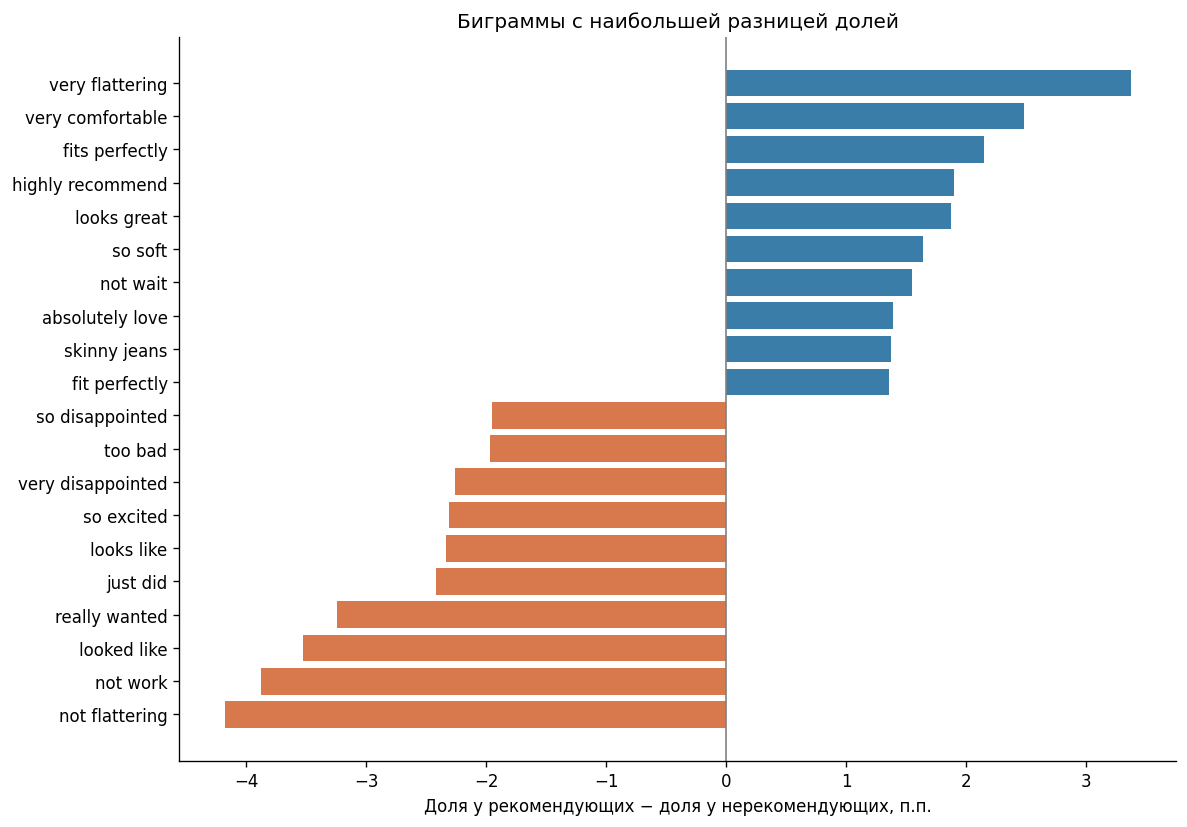

In [8]:
comparison = freq[('Биграммы',0)][['term','reviews','reviews_pct']].merge(
    freq[('Биграммы',1)][['term','reviews','reviews_pct']],on='term',how='outer',suffixes=('_0','_1')).fillna(0)
comparison = comparison.loc[(comparison.reviews_0+comparison.reviews_1)>=30].copy()
comparison['difference_pp'] = comparison.reviews_pct_1 - comparison.reviews_pct_0
comparison = comparison.sort_values('difference_pp')
selected = pd.concat([comparison.head(10),comparison.tail(10)]).drop_duplicates('term')
plt.figure(figsize=(10,7))
plt.barh(selected.term,selected.difference_pp,color=[COLORS[int(x>0)] for x in selected.difference_pp])
plt.axvline(0,color='gray',linewidth=1)
plt.xlabel('Доля у рекомендующих − доля у нерекомендующих, п.п.')
plt.title('Биграммы с наибольшей разницей долей'); plt.tight_layout(); plt.show()
negative_terms = ', '.join(comparison.head(3).term)
positive_terms = ', '.join(comparison.tail(3).iloc[::-1].term)

## 5. Рекомендации по категориям одежды
Здесь используем все строки, включая записи без текста, т.к. метка рекомендации у них известна.

Рядом с долей показываем число отзывов и 95%-й доверительный интервал. Для маленьких категорий оценка менее устойчива. Интервалы условно считают отзывы независимыми; повторные отзывы об одной вещи могут делать реальную неопределенность больше.

,n,recommended,"Доля, %","Нижняя, %","Верхняя, %"
Class Name,,,,,
Trend,119,88,73.9,65.4,81.0
Sweaters,1428,1143,80.0,77.9,82.0
Swim,350,282,80.6,76.1,84.4
Dresses,6319,5107,80.8,79.8,81.8
Blouses,3097,2509,81.0,79.6,82.4
Outerwear,328,268,81.7,77.2,85.5
Knits,4843,3960,81.8,80.7,82.8
Pants,1388,1156,83.3,81.2,85.2
Fine gauge,1100,921,83.7,81.4,85.8


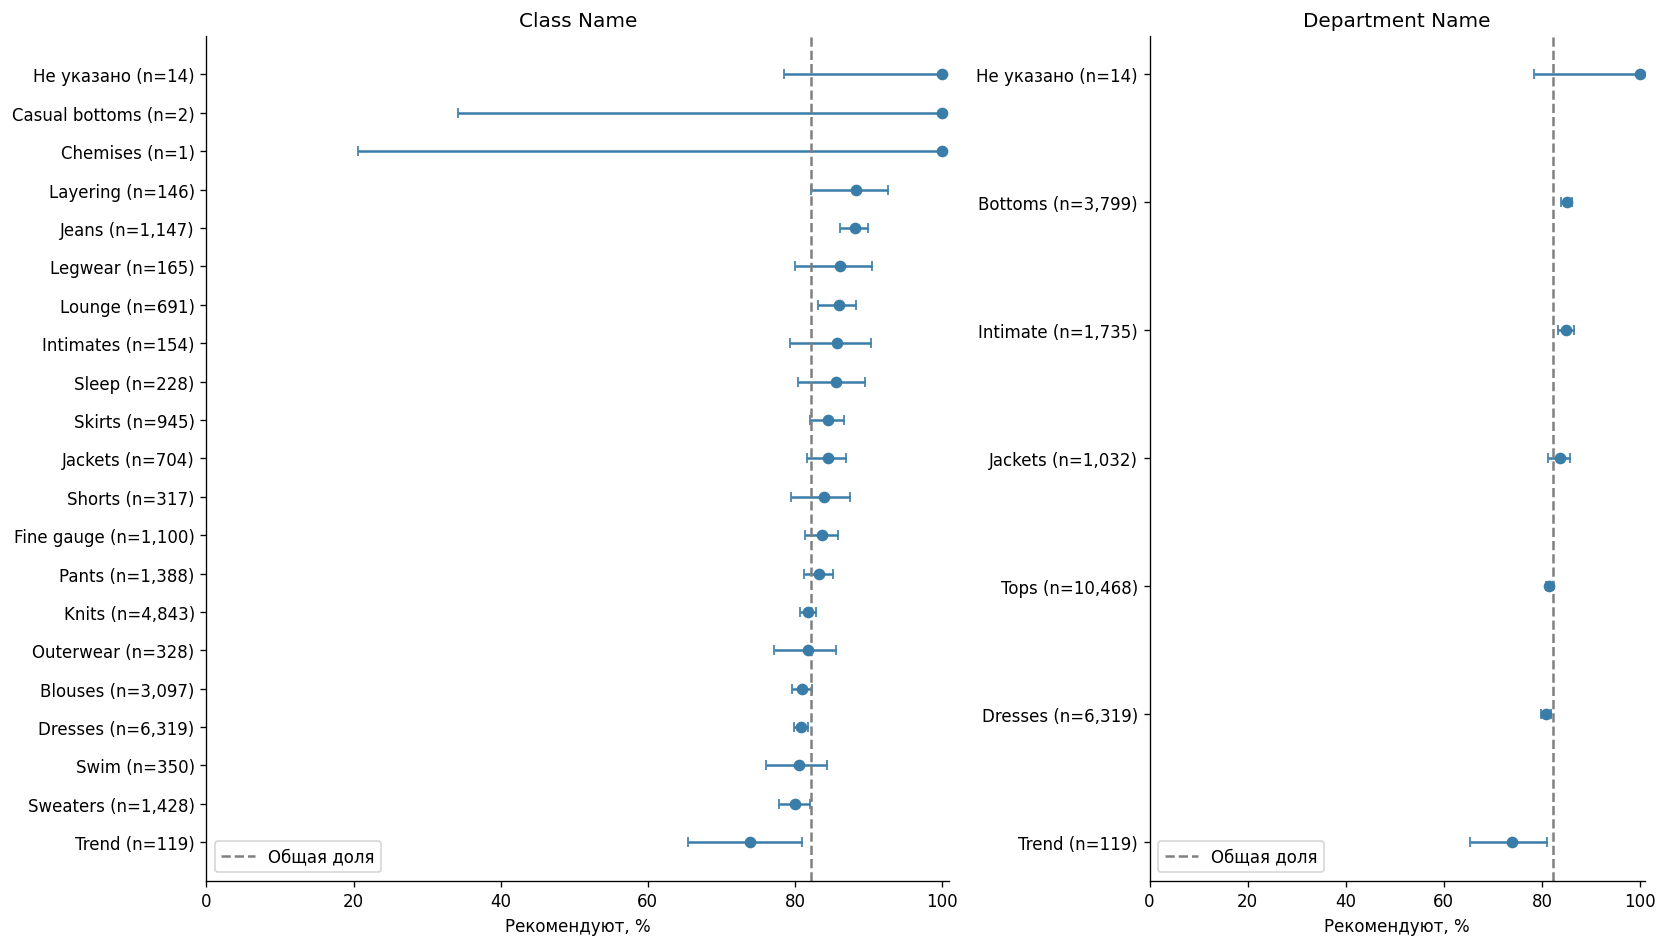

In [9]:
def category_summary(column):
    summary = df.groupby(df[column].fillna('Не указано'))['Recommended IND'].agg(n='size', recommended='sum')
    n = summary.n; p = summary.recommended/n; z = 1.96
    denominator = 1+z*z/n
    center = (p+z*z/(2*n))/denominator
    radius = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denominator
    return summary.assign(rate=p, low=center-radius, high=center+radius).sort_values('rate')

categories = category_summary('Class Name')
display(categories.assign(**{'Доля, %':categories.rate*100,
                              'Нижняя, %':categories.low*100,'Верхняя, %':categories.high*100})
        .drop(columns=['rate','low','high']).round(1))
fig, axes = plt.subplots(1,2,figsize=(14,8),gridspec_kw={'width_ratios':[1.5,1]})
for ax,column in zip(axes,['Class Name','Department Name']):
    tab = category_summary(column)
    y = np.arange(len(tab))
    ax.errorbar(tab.rate*100,y,xerr=[(tab.rate-tab.low)*100,(tab.high-tab.rate)*100],fmt='o',color='#397DA8',capsize=3)
    ax.set_yticks(y,[f'{name} (n={n:,})' for name,n in zip(tab.index,tab.n)])
    ax.axvline(df['Recommended IND'].mean()*100,linestyle='--',color='gray',label='Общая доля')
    ax.set(xlim=(0,101),xlabel='Рекомендуют, %',title=column); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()
large = categories.query('n >= 100')

**Вывод.** Среди категорий с ≥100 отзывами доля рекомендаций лежит от 74% (Trend) до 88% (Layering). Категорию можно проверить как дополнительный признак. Рейтинг категорий с единичными отзывами ненадежен; сами различия не доказывают, что причина именно в категории одежды.

## 6. Короткие отзывы и пустой ввод
Пусть основной порог короткого отзыва это не более 5 слов, без пустых текстов. Дополнительно проверяем пороги 3 и 10 слов. Короткий отзыв может быть вполне содержательным.

In [10]:
short_rows = []
for threshold in [3,5,10]:
    mask = text_df.n_words.le(threshold)
    short_rows.append({'Порог слов':threshold,'Отзывов':int(mask.sum()),
                       'Доля текстов, %':mask.mean()*100,
                       'Рекомендуют, %':text_df.loc[mask,'Recommended IND'].mean()*100})
display(pd.DataFrame(short_rows).round(2))
df['length_group'] = pd.cut(df.n_words,bins=[-1,0,5,20,50,100,np.inf],
                            labels=['0 слов','1–5','6–20','21–50','51–100','101+'])
length_groups = df.groupby('length_group',observed=True).agg(
    n=('Recommended IND','size'),recommend_pct=('Recommended IND',lambda x:x.mean()*100))
display(length_groups.round(2))
short = text_df.loc[text_df.n_words.le(5)]
for target in [0,1]:
    display(Markdown('**Примеры: '+LABELS[target]+'**'))
    examples = short.loc[short['Recommended IND'].eq(target),['Review Text','n_words','Rating']]
    display(examples.sample(n=min(5,len(examples)),random_state=42))

,Порог слов,Отзывов,"Доля текстов, %","Рекомендуют, %"
0,3,19,0.08,89.47
1,5,52,0.23,90.38
2,10,360,1.59,90.56


,n,recommend_pct
length_group,,
0 слов,845,91.60
1–5,52,90.38
6–20,1996,88.03
21–50,7375,81.80
51–100,12122,80.72
101+,1096,83.76


**Примеры: Не рекомендует**

,Review Text,n_words,Rating
9121,"Very pretty, romantic",3,3
22126,Super itchy! had to return.,5,1
11214,"Low waisted, weird liner.",4,3
8605,Totally see through.,3,1
16863,I never write reviews,4,3


**Примеры: Рекомендует**

,Review Text,n_words,Rating
14814,Great dress for vacations!,4,5
21461,Nice print and comfortable shirt.,5,5
14632,Beautiful and comfy!!!! love it!,5,5
22499,Great fit and extremely comfortable.,5,5
14101,This is a wonderful style.,5,5


**Вывод.** Отзывов до 5 слов всего 0.2% от непустых текстов, до 10 слов доля 1.6%. Короткие отзывы не обязательно удалять автоматически, ведь даже несколько слов могут ясно выражать оценку.

## 7. Дополнительные проверки
### Рейтинг и рекомендация
Рейтинг используем только для проверки данных, т.к. сервис не получает его на вход

Recommended IND,Не рекомендует,Рекомендует,recommend_pct
Rating,,,
1,826,16,1.90
2,1471,94,6.01
3,1682,1189,41.41
4,168,4909,96.69
5,25,13106,99.81


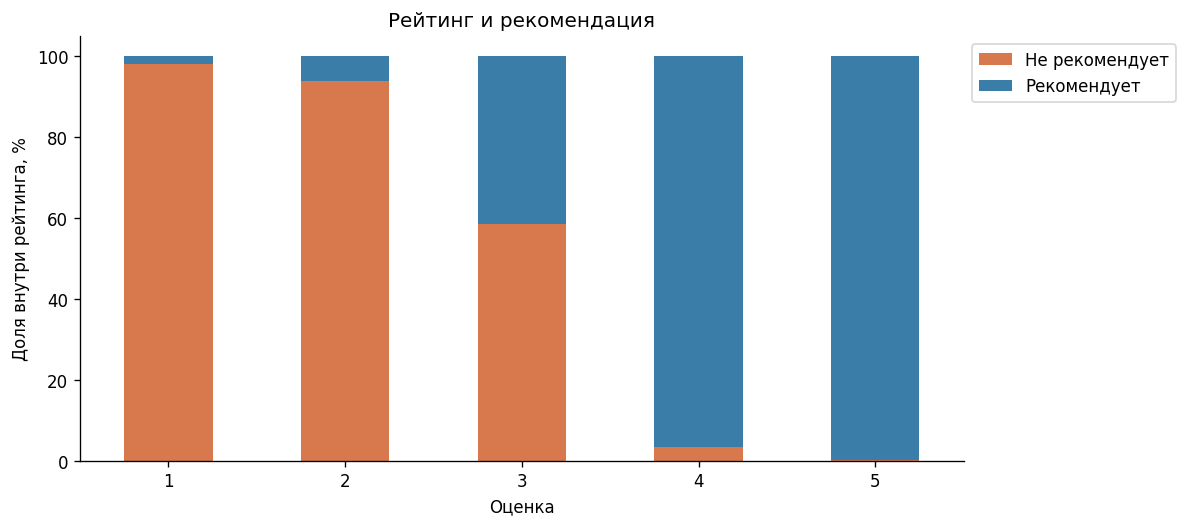

In [11]:
rating_counts = pd.crosstab(df.Rating,df['Recommended IND']).reindex(columns=[0,1],fill_value=0)
rating_shares = rating_counts.div(rating_counts.sum(axis=1),axis=0)*100
display(rating_counts.rename(columns=LABELS).assign(recommend_pct=rating_shares[1]).round(2))
rating_shares.rename(columns=LABELS).plot.bar(stacked=True,color=[COLORS[0],COLORS[1]],rot=0)
plt.ylabel('Доля внутри рейтинга, %'); plt.xlabel('Оценка'); plt.title('Рейтинг и рекомендация'); plt.legend(loc='upper left',bbox_to_anchor=(1,1)); plt.tight_layout(); plt.show()
low_yes = ((df.Rating<=2)&df['Recommended IND'].eq(1)).sum()
high_no = ((df.Rating>=4)&df['Recommended IND'].eq(0)).sum()

**Вывод.** Есть 110 рекомендаций с оценкой 1–2 и 193 отказов рекомендовать с оценкой 4–5. Рекомендация и оценка связаны, но не совпадают. Не думаю, что такие строки стоит автоматически считать ошибками или переопределять их метку по рейтингу, т.к. покупательнице может не подойти товар, но она все равно готова порекоммендовать его другим. Возможно их стоит просто удалить, тк их мало

### Дубликаты текстов и повторяющиеся товары
Проверяем полные повторы без служебного индекса, а также тексты после приведения к нижнему регистру и нормализации пробелов. Пустые тексты не считаем дубликатами. Одинаковая короткая фраза может быть независимым отзывом, поэтому удалять все совпадения без разбора не стоит.

In [12]:
text_df['normalized_text'] = text_df['Review Text'].str.lower().str.replace(r'\s+',' ',regex=True).str.strip()
text_groups = text_df.groupby('normalized_text').agg(n=('Recommended IND','size'),
    labels=('Recommended IND','nunique'))
duplicate_groups = text_groups.query('n > 1')
conflicts = duplicate_groups.query('labels > 1')
full_duplicates = raw.drop(columns=[c for c in raw if c.startswith('Unnamed:')]).duplicated().sum()
product_counts = text_df['Clothing ID'].value_counts()
display(pd.Series({
    'Полные дубликаты сверх первой строки':int(full_duplicates),
    'Группы повторяющихся текстов':len(duplicate_groups),
    'Строки в группах повторяющихся текстов':int(duplicate_groups.n.sum()),
    'Повторы текстов сверх первого':int((duplicate_groups.n-1).sum()),
    'Повторяющиеся тексты с разными метками':len(conflicts),
    'Уникальные товары среди строк с текстом':len(product_counts),
    'Товары с несколькими отзывами':int(product_counts.gt(1).sum())}).to_frame('Количество'))
if len(duplicate_groups):
    display(duplicate_groups.sort_values('n',ascending=False).head(8))

,Количество
Полные дубликаты сверх первой строки,21
Группы повторяющихся текстов,6
Строки в группах повторяющихся текстов,13
Повторы текстов сверх первого,7
Повторяющиеся тексты с разными метками,0
Уникальные товары среди строк с текстом,1179
Товары с несколькими отзывами,705


,n,labels
normalized_text,,
perfect fit and i've gotten so many compliments. i buy all my suits from here now!,3,1
"i bought this shirt at the store and after going home and trying it on, i promptly went online and ordered two more! i've gotten multiple compliments anytime i wear any of them. great for looking put together with no fuss. people that have commented there's were destroyed in the wash didn't read the care label which says dry clean.",2,1
"i purchased this and another eva franco dress during retailer's recent 20% off sale. i was looking for dresses that were work appropriate, but that would also transition well to happy hour or date night. they both seemed to be just what i was looking for. i ordered a 4 regular and a 6 regular, as i am usually in between sizes. the 4 was definitely too small. the 6 fit, technically, but was very ill fitting. not only is the dress itself short, but it is very short-waisted. i am only 5'3"", but it fe",2,1
"lightweight, soft cotton top and shorts. i think it's meant to be a beach cover-up but i'm wearing it as a thin, light-weight summer outfit on these hot hot days. the top has a loose elastic around the bottom which i didn't realize when i ordered it, but i like it and it matches the look in the photos. and the shorts are very low-cut - don't expect them up around your waist. again, i like that. some might want to wear a cami underneath because it's a thin cotton but i'm fine as-is. i bought it i",2,1
"love, love these jeans. being short they come right to my ankle. super soft and don?t require any hemming. i ordered my typical jean size of 26 and they fit like a glove. would love to have these in black and grey.",2,1
"the sweater and skirt are so pretty! they're really soft and have such an easy, comfortable look together. really love this gorgeous outfit. i am borderline small/medium and kept the size small after trying both on.",2,1


**Вывод.** Совпадающие тексты могут попасть одновременно в обучение и тест и завысить качество. При разбиении нужно контролировать их пересечение.

## 8. Общие выводы

- **Классы несбалансированы.** Сравниваем модель с DummyClassifier; основные метрики - Macro-F1 и F1 класса «не рекомендует».
- **Пустой текст обрабатываем отдельно.** Для текстовой модели используем непустые отзывы. Заголовок можно добавить отдельным экспериментом.
- **Слова важны вместе с контекстом.** Начинаем с TF-IDF + Logistic Regression; сравниваем слова и слова + биграммы.
- **Короткие отзывы можно сохранить.** Их крайне мало, но они могут быть содержательными. Отдельно можно оцениваем качество на коротких и длинных текстах.
- **Перед обучением фиксируем разбиение и контролируем дубликаты.**



